# Упражнения по Boosting and Stacking 

![Boosting.png](Assets/Boosting.png)

# Цели обучения

- Объяснить, как алгоритм бустинга помогает снизить дисперсию и систематическую ошибку.

## Введение

Мы будем использовать базу данных [«Распознавание действий человека с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), сформированную на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

In [12]:
from __future__ import print_function
import os
data_path = [ 'data']
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import VotingClassifier

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    pass



Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные из файла `Human_Activity_Recognition_Using_Smartphones_Data.csv` и проанализируйте структуру и типы данных. Типов данных будет слишком много, чтобы перечислять их по каждому столбцу отдельно. Вместо этого сгруппируйте типы по количеству.
* Определите, требуется ли масштабирование столбцов с числами типа float.

In [4]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')


В наборе данных довольно много столбцов с предикторами.

In [5]:
data.dtypes.value_counts()


float64    561
object       1
Name: count, dtype: int64

И все они — значения типа float. Единственное значение, не относящееся к типу float, — это столбец «categories», который и является объектом прогнозирования.

In [6]:
float_cols = data.select_dtypes(include='float64').columns
print('min:', data[float_cols].min().min())
print('max:', data[float_cols].max().max())


min: -1.0
max: 1.0


Минимальное и максимальное значения для столбцов типа float составляют -1,0 и 1,0 соответственно. Однако для методов, основанных на дереве, масштабирование никогда не требуется.

## Вопрос 2

* Присвойте действиям целочисленные коды.
* Разделите данные на обучающий и тестовый наборы. Решите, будет ли производиться стратификация данных при разделении на обучающий и тестовый наборы или нет.

**ПРИМЕЧАНИЕ**: Мы собираемся создать обучающий и тестовый наборы данных из `data`. На этих наборах данных мы будем проводить поиск по сетке с различными значениями параметров. Это может занять некоторое время. Чтобы сократить время поиска по сетке, вы можете уменьшить разрешение `data` и создать `X_train, X_test, y_train, y_test` на основе набора данных с уменьшенным разрешением.

Теперь разделите данные на обучающий и тестовый наборы. Здесь не использовалось стратифицированное деление. Если возникнут проблемы с какими-либо метриками ошибок на тестовом наборе, может быть целесообразно начать подбор модели с использованием стратифицированного деления. Однако метод бустинга является довольно мощной моделью, поэтому в данном случае это может оказаться ненужным.

In [7]:
le = LabelEncoder()
data['activity_code'] = le.fit_transform(data['Activity'])

feature_cols = [c for c in data.columns if c not in ('Activity', 'activity_code')]
X = data[feature_cols]
y = data['activity_code']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train.shape, X_test.shape


((7209, 561), (3090, 561))

In [8]:
# уменьшенная версия для поиска по сетке (вопросы 4 и 5), чтобы не ждать слишком долго
data_small = data.sample(frac=0.25, random_state=42)
X_small = data_small[feature_cols]
y_small = data_small['activity_code']

X_train_small, X_test_small, y_train_small, y_test_small = train_test_split(
    X_small, y_small, test_size=0.3, random_state=42)
X_train_small.shape


(1802, 561)

## Вопрос 3

* Постройте модели градиентного бустинга с деревьями, установив все параметры по умолчанию, для следующих значений количества деревьев (`n_estimators = [25, 50, 100, 200, 400]`) и оцените точность на тестовых данных для каждой из этих моделей.
* Постройте график зависимости точности от количества оценок.

**Примечание:** Выполнение этого задания может занять некоторое время в зависимости от количества различных значений, подбираемых для оценок. Установка параметра `max_features=4` в классификаторе градиентного бустинга увеличит скорость сходимости.

Кроме того, это задание аналогично заданию 3 из 9-й недели, за исключением того, что для моделей с бустингом не существует такого понятия, как «ошибка out-of-bag». Кроме того, в модели градиентного бустинга присутствует ошибка в настройке `warm_flag=True`, поэтому не используйте её. Просто создайте модель внутри цикла `for` и задайте количество оценок в этот момент. Это приведёт к тому, что подбор модели займёт немного больше времени. Кроме того, подбор моделей бустинга, как правило, занимает больше времени, чем подбор моделей методом bagging, поскольку «решающие пеньки» необходимо подбирать последовательно.

In [9]:
tree_counts = [25, 50, 100, 200, 400]
rows = []

for n in tree_counts:
    gb = GradientBoostingClassifier(n_estimators=n, max_features=4, random_state=42)
    gb.fit(X_train, y_train)
    acc = accuracy_score(y_test, gb.predict(X_test))
    rows.append({'n_trees': n, 'accuracy': acc})

gb_acc_df = pd.DataFrame(rows).set_index('n_trees')
gb_acc_df


,accuracy
n_trees,
25,0.931068
50,0.959547
100,0.976375
200,0.984142
400,0.986731


Теперь построим график результата.

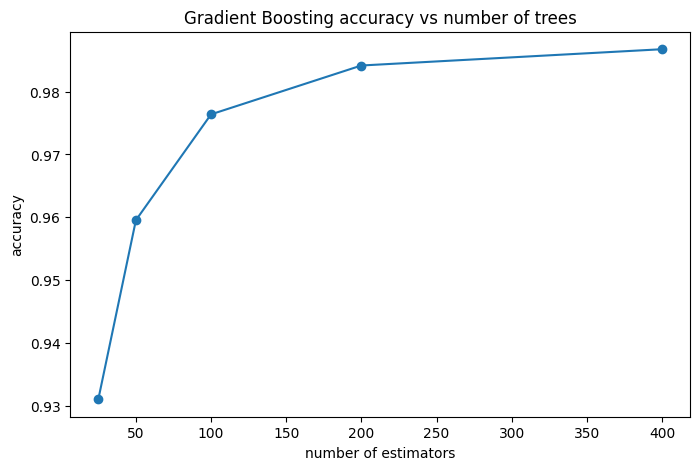

In [14]:
gb_acc_df.plot(marker='o', legend=False, figsize=(8, 5))
plt.xlabel('number of estimators')
plt.ylabel('accuracy')
plt.title('Gradient Boosting accuracy vs number of trees')
plt.show()


## Вопрос 4

* Используя поиск по сетке с перекрестной валидацией, постройте новый классификатор с градиентным бустингом, используя список оценок, аналогично вопросу 3. Также рассмотрите возможность изменения скоростей обучения (0,1; 0,01; 0,001 и т. д.), значения подвыборки (1,0 или 0,5) и количества максимальных признаков (1, 2 и т. д.).
* Проанализируйте параметры модели с наилучшей подгонкой.
* Рассчитайте соответствующие метрики ошибок для этой модели и проанализируйте матрицу путаницы.

**Примечание:** выполнение этого вопроса может занять некоторое время в зависимости от количества признаков, используемых в поиске по сетке. Рекомендуется начать с небольшого количества, чтобы убедиться в корректной работе, а затем добавить больше признаков. Установка параметра `max_features=4` в классификаторе с градиентным бустингом увеличит скорость сходимости.

In [15]:
gb_param_grid = {
    'n_estimators': [25, 100, 200],
    'learning_rate': [0.1, 0.01],
    'subsample': [1.0, 0.5],
    'max_features': [2, 4],
}

gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=42), gb_param_grid, cv=3, n_jobs=-1)
gb_grid.fit(X_train_small, y_train_small)

gb_grid.best_params_


{'learning_rate': 0.1,
 'max_features': 4,
 'n_estimators': 200,
 'subsample': 0.5}

In [16]:
# переобучаем лучшую модель уже на полном обучающем наборе
gb_best = GradientBoostingClassifier(random_state=42, **gb_grid.best_params_)
gb_best.fit(X_train, y_train)

y_pred_gb = gb_best.predict(X_test)
accuracy_score(y_test, y_pred_gb)


0.9815533980582525

Показатели ошибок. Отчет о классификации особенно удобен в случаях с несколькими классами.

In [17]:
print(classification_report(y_test, y_pred_gb, target_names=le.classes_))


                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       597
           SITTING       0.96      0.95      0.96       563
          STANDING       0.96      0.96      0.96       547
           WALKING       0.99      1.00      1.00       539
WALKING_DOWNSTAIRS       1.00      0.99      0.99       420
  WALKING_UPSTAIRS       0.98      1.00      0.99       424

          accuracy                           0.98      3090
         macro avg       0.98      0.98      0.98      3090
      weighted avg       0.98      0.98      0.98      3090



Матрица путаницы. Обратите внимание, что модель с градиентным бустингом испытывает небольшие затруднения при различении классов активности 1 и 2.

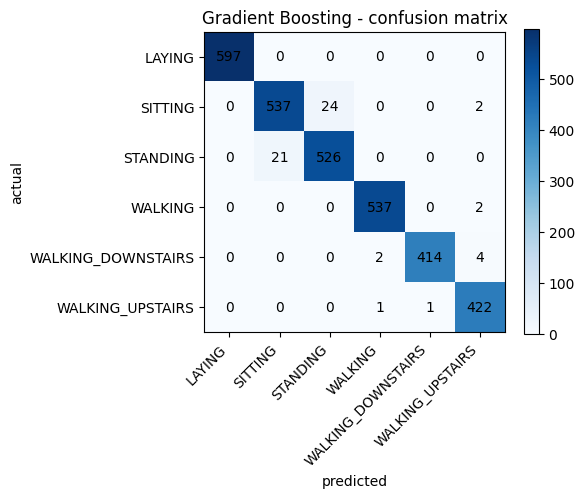

In [18]:
cm_gb = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(6, 5))
plt.imshow(cm_gb, cmap='Blues')
plt.colorbar()
plt.xticks(range(6), le.classes_, rotation=45, ha='right')
plt.yticks(range(6), le.classes_)
for i in range(6):
    for j in range(6):
        plt.text(j, i, cm_gb[i, j], ha='center', va='center')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('Gradient Boosting - confusion matrix')
plt.tight_layout()
plt.show()


## Вопрос 5

* Создайте модель AdaBoost и подстройте её с помощью поиска по сетке, аналогично вопросу 4. Попробуйте использовать различные значения оценщика в диапазоне от 100 до 200.
* Сравните погрешности модели AdaBoost с погрешностями модели GradientBoostedClassifier.

**ПРИМЕЧАНИЕ:** Установка параметра `max_features=4` в классификаторе на основе дерева решений, используемом в качестве базового классификатора для AdaBoost, повысит скорость сходимости.

In [19]:
ada_param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.5, 1.0],
}

ada_base = DecisionTreeClassifier(max_depth=2, max_features=4, random_state=42)
ada_grid = GridSearchCV(AdaBoostClassifier(estimator=ada_base, random_state=42), ada_param_grid, cv=3, n_jobs=-1)
ada_grid.fit(X_train_small, y_train_small)

ada_grid.best_params_


{'learning_rate': 0.5, 'n_estimators': 200}

Лучшая модель.

In [20]:
ada_best = AdaBoostClassifier(estimator=ada_base, random_state=42, **ada_grid.best_params_)
ada_best.fit(X_train, y_train)

y_pred_ada = ada_best.predict(X_test)
accuracy_score(y_test, y_pred_ada)


0.9378640776699029

Показатели ошибок. Обратите внимание, что проблемы с классами 1 и 2, по-видимому, усугубились и теперь затрагивают также класс 0. Также обратите внимание на другие проблемы, связанные с классами 3–5. Алгоритм AdaBoost очень чувствителен к выбросам, поэтому именно в этом может заключаться причина проблемы.

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       597
           SITTING       0.88      0.84      0.86       563
          STANDING       0.85      0.89      0.87       547
           WALKING       0.99      0.97      0.98       539
WALKING_DOWNSTAIRS       0.96      0.97      0.97       420
  WALKING_UPSTAIRS       0.95      0.97      0.96       424

          accuracy                           0.94      3090
         macro avg       0.94      0.94      0.94      3090
      weighted avg       0.94      0.94      0.94      3090



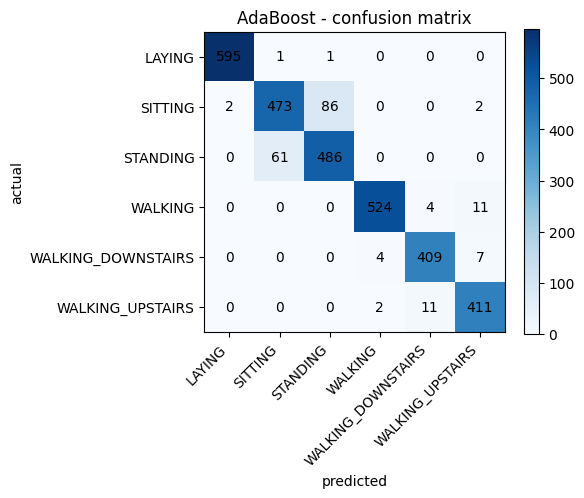

In [21]:
print(classification_report(y_test, y_pred_ada, target_names=le.classes_))

cm_ada = confusion_matrix(y_test, y_pred_ada)
plt.figure(figsize=(6, 5))
plt.imshow(cm_ada, cmap='Blues')
plt.colorbar()
plt.xticks(range(6), le.classes_, rotation=45, ha='right')
plt.yticks(range(6), le.classes_)
for i in range(6):
    for j in range(6):
        plt.text(j, i, cm_ada[i, j], ha='center', va='center')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('AdaBoost - confusion matrix')
plt.tight_layout()
plt.show()


## Вопрос 6

* Постройте модель логистической регрессии с регуляризацией. Это может быть аналог модели, которая хорошо себя показала в упражнениях 4-й недели.
* Используя `VotingClassifier`, постройте модель логистической регрессии вместе с моделью GratientBoostedClassifier или AdaBoost (или обеими) из вопросов 4 и 5.
* Определите ошибку, как и ранее, и сравните результаты с соответствующими моделями с градиентным бустингом.
* Постройте матрицу путаницы для лучшей модели, созданной в этом наборе упражнений.

In [22]:
lr = LogisticRegressionCV(Cs=5, cv=3, max_iter=1000, random_state=42, n_jobs=-1)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
accuracy_score(y_test, y_pred_lr)


c:\Program Files\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Program Files\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
c:\Program Files\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=Fals

0.9799352750809062

Проверьте ошибки и матрицу путаницы для модели логистической регрессии.

In [23]:
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))


                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       597
           SITTING       0.96      0.95      0.95       563
          STANDING       0.95      0.96      0.95       547
           WALKING       0.99      1.00      1.00       539
WALKING_DOWNSTAIRS       1.00      0.99      0.99       420
  WALKING_UPSTAIRS       0.98      1.00      0.99       424

          accuracy                           0.98      3090
         macro avg       0.98      0.98      0.98      3090
      weighted avg       0.98      0.98      0.98      3090



А теперь — многоуровневая модель (stacked model).

In [24]:
voting_clf = VotingClassifier(
    estimators=[('lr', lr), ('gb', gb_best), ('ada', ada_best)],
    voting='hard'
)
voting_clf.fit(X_train, y_train)

y_pred_vote = voting_clf.predict(X_test)
accuracy_score(y_test, y_pred_vote)


c:\Program Files\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Program Files\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
c:\Program Files\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=Fals

0.9799352750809062

Наконец, рассмотрим ошибку классификатора при голосовании. Здесь мы показываем немного лучшие результаты, чем при использовании либо логистической регрессии, либо градиентных бустеров по отдельности. Однако тот факт, что логистическая регрессия демонстрирует почти такие же результаты, как и градиентные бустеры, служит важным напоминанием о том, что сначала следует пробовать самую простую модель. В некоторых случаях её эффективности будет вполне достаточно.

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       597
           SITTING       0.96      0.95      0.95       563
          STANDING       0.95      0.95      0.95       547
           WALKING       0.99      1.00      1.00       539
WALKING_DOWNSTAIRS       1.00      0.99      0.99       420
  WALKING_UPSTAIRS       0.98      1.00      0.99       424

          accuracy                           0.98      3090
         macro avg       0.98      0.98      0.98      3090
      weighted avg       0.98      0.98      0.98      3090



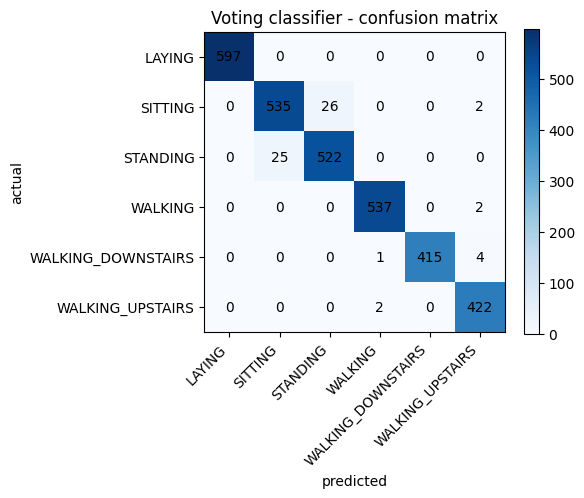

In [25]:
print(classification_report(y_test, y_pred_vote, target_names=le.classes_))

cm_vote = confusion_matrix(y_test, y_pred_vote)
plt.figure(figsize=(6, 5))
plt.imshow(cm_vote, cmap='Blues')
plt.colorbar()
plt.xticks(range(6), le.classes_, rotation=45, ha='right')
plt.yticks(range(6), le.classes_)
for i in range(6):
    for j in range(6):
        plt.text(j, i, cm_vote[i, j], ha='center', va='center')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('Voting classifier - confusion matrix')
plt.tight_layout()
plt.show()
